# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

> **Registro de cambios de esta corrida**
> - **No se modificó ninguna constante** de esta sección (`SIZES`, `SEEDS`, `MAX_EPOCHS`, `PATIENCE`, `BATCH`, `AUG_COPIES`, `SEED_SPLIT=42`, `SEEDS_FINAL`).
> - Se agregó una celda inicial que descarga el dataset desde el repositorio de la cátedra a `data/Split_smol` (necesaria para correr en Colab).
> - Entorno: Google Colab con **GPU T4** (`Dispositivo: cuda`, torch 2.14.1). Los tiempos por época de las tablas son de esa GPU y no son comparables con los ~20 min en CPU que menciona el enunciado.
> - En GPU el entrenamiento **no es determinista** (cuDNN): la misma config base con las mismas semillas dio val_acc 0.633 (sección 5), 0.649 (sección 6) y 0.631 (sección 7). Uso esa dispersión (~0.02) como referencia adicional de ruido.

In [5]:
%cd /content
!git clone -q --depth 1 https://github.com/2245-RN-ITBA/skin-dataset-classification.git /content/skin
!mkdir -p data && cp -r /content/skin/data/Split_smol data/
!ls data/Split_smol/train | wc -l


/content
9


In [6]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [7]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 10s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


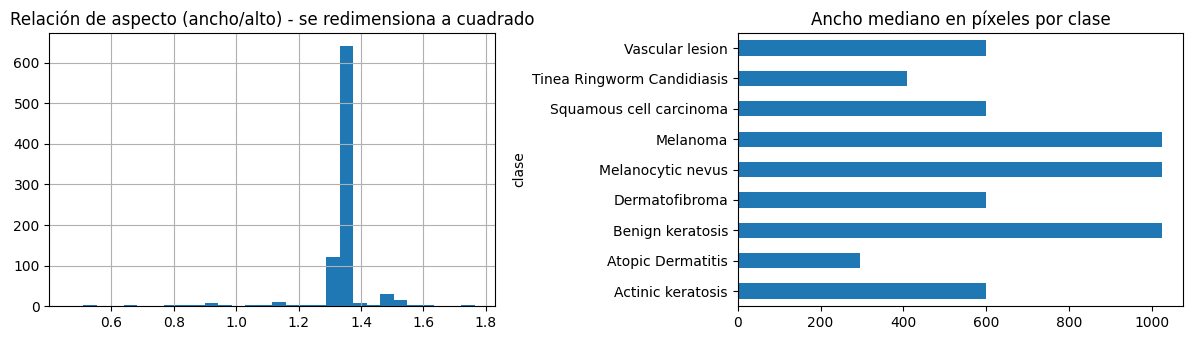

In [8]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

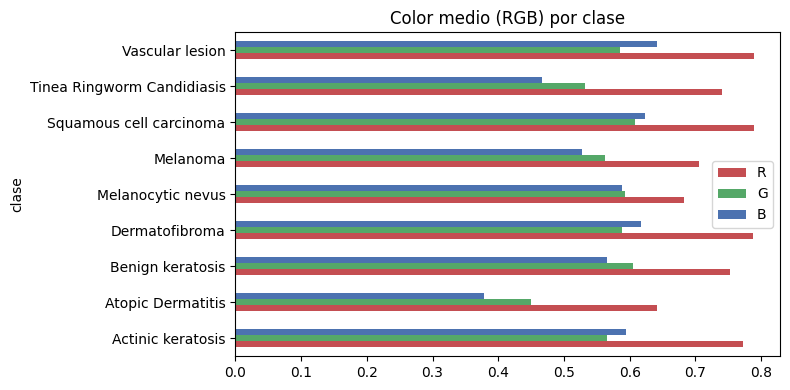

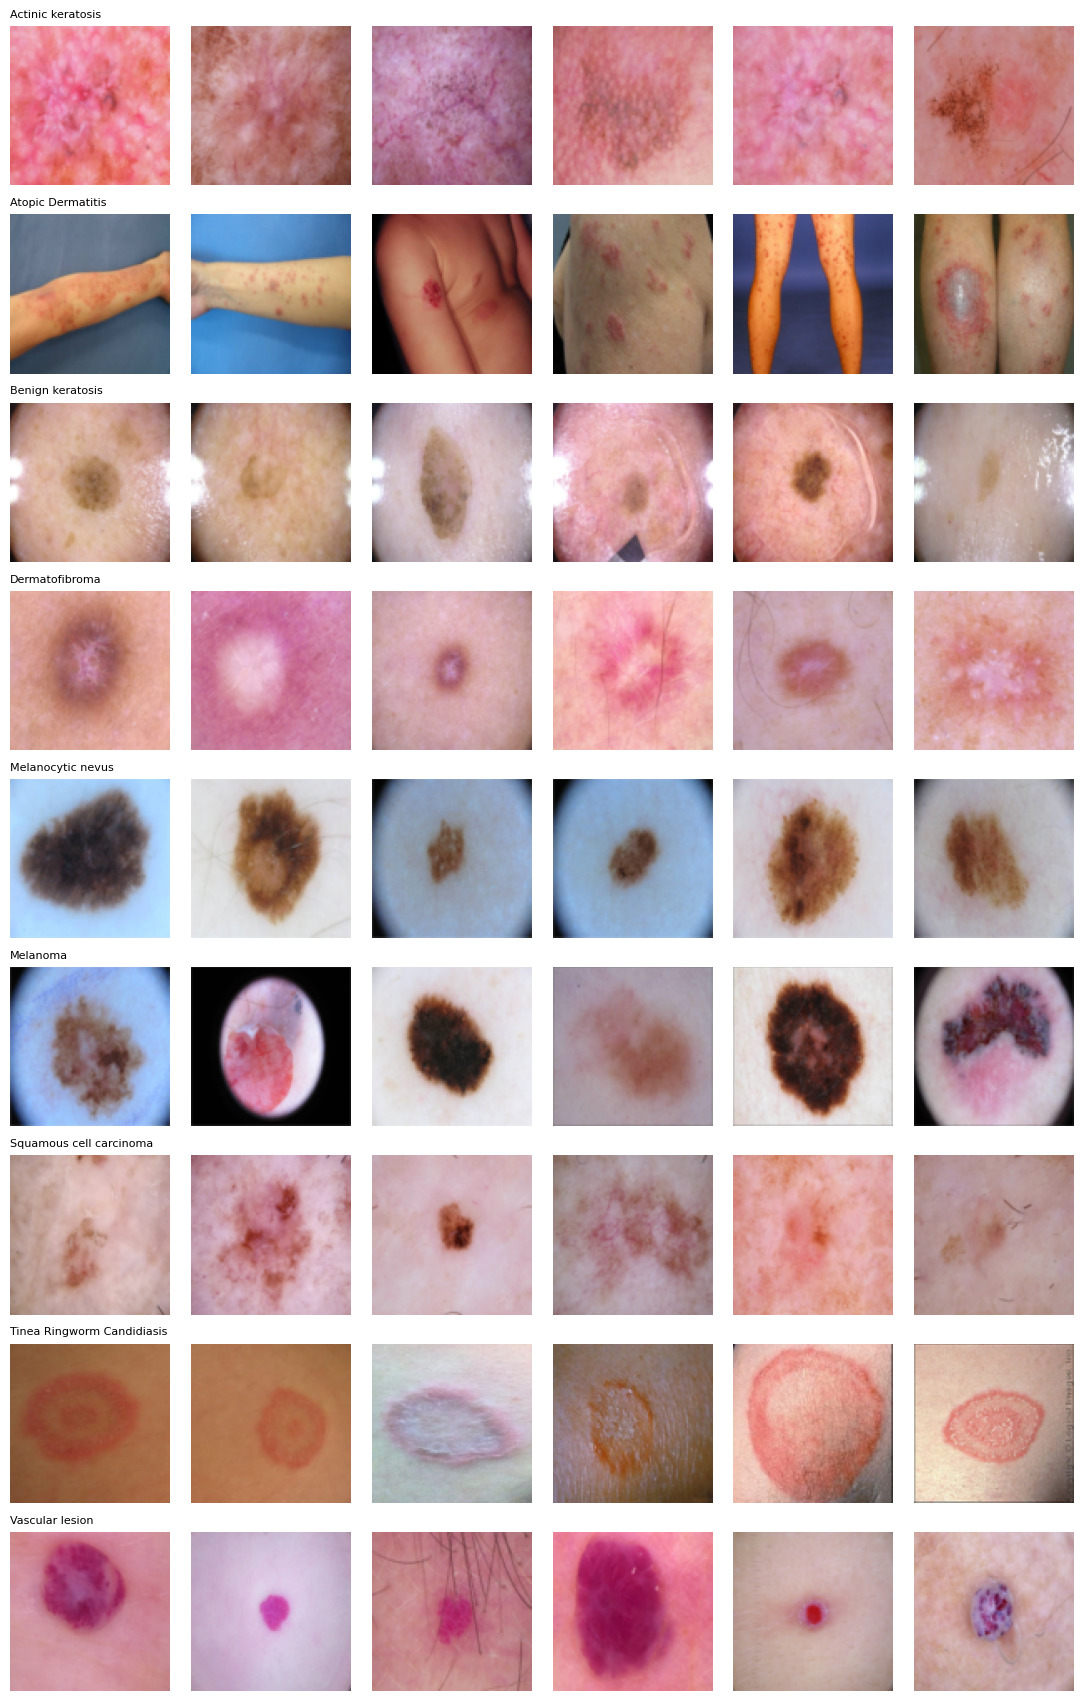

In [9]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [10]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

**1. Desbalance.** Hay 878 imágenes: 8 clases tienen ~100 (80 train / 20 val) y *Tinea Ringworm Candidiasis* tiene 76 (56/20), así que el desbalance original es leve (1.3:1). Pero ese balance es en parte artificial: después de eliminar duplicados (sección 2) *Atopic Dermatitis* baja de 102 a 80 imágenes y *Tinea* de 76 a 64, y el cociente máximo pasa a 100/64 ≈ 1.6:1. En el split nuevo, train queda con 60 imágenes por clase salvo Atopic (48) y Tinea (38). Además, la partición original no tenía test.

**2. Resolución y color por clase.** La resolución está casi totalmente determinada por la clase: *Atopic Dermatitis* es 100 % 294×222; *Actinic keratosis*, *Dermatofibroma*, *Squamous cell carcinoma* y *Vascular lesion* son 100 % 600×450; *Benign keratosis* es 74 % 1024×764; *Melanocytic nevus* 79 % 1024×768 (+18 % 1022×767); *Melanoma* 56 % 1024×768 y 41 % "otras"; *Tinea* es 100 % "otras" (ancho mediano ~400 px). La relación de aspecto es ~1.33 (4:3) en casi todas, así que el redimensionado a cuadrado las deforma a todas por igual y no es una pista fuerte. El redimensionado elimina la resolución como dato explícito, pero **no elimina las huellas de la fuente de adquisición**, que se ven en los ejemplos: *Atopic* y *Tinea* son fotos clínicas (brazos, piernas, fondos azules o negros), no dermatoscopías, y por eso *Atopic* tiene un color medio mucho más oscuro (R 0.64, G 0.45, B 0.38 contra R entre 0.68 y 0.79 en el resto); *Benign keratosis* tiene reflejos blancos de flash a los costados; *nevus* y *melanoma* tienen viñetas circulares negras o azules. **Riesgo:** *shortcut learning*. El modelo puede aprender "de qué cámara o fuente viene la imagen" en lugar de la lesión, lo que infla el accuracy en este dataset y no generaliza a imágenes de otra fuente. Las clases que comparten fuente (AK/DF/SCC/VL a 600×450; nevus/melanoma a 1024×768) solo se pueden separar con rasgos reales de la lesión, así que ahí espero las confusiones.

**3. Duplicados.** Hay 34 grupos de imágenes idénticas por MD5 (34 pares), 33 de ellos repartidos entre `train/` y `val/`, todos en *Atopic Dermatitis* (22) y *Tinea* (12), sin conflictos de etiqueta. El hash perceptual encuentra los mismos 34 pares y ningún casi-duplicado adicional (con umbral ≤ 8 bits). Como val de Atopic tiene 21 imágenes y hay 33 grupos cruzados de los cuales a lo sumo 12 son de Tinea, **las 21 imágenes de val de Atopic eran copias de imágenes de train**, y 12 de las 20 de Tinea también. En total, 33 de las 181 imágenes de val (18 %) ya las había visto el modelo. Sin eliminarlas, la `val_acc` mediría memorización para esas imágenes: si el modelo acierta ~63 % en imágenes nuevas y entre 80 % y 100 % en las memorizadas, la val_acc subiría a ~0.66-0.70, es decir, **entre 3 y 7 puntos de mejora ficticia**, concentrada en el recall de Atopic y Tinea.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [11]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

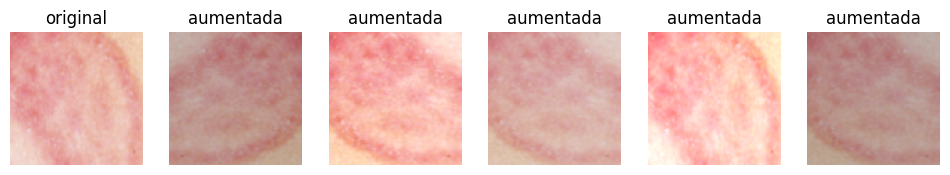

In [12]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [13]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [14]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

**1. `padding=kernel // 2`.** El tamaño de salida de una convolución con stride 1 es `H_out = H + 2p − k + 1`. Con k = 3 y p = 3 // 2 = 1: 64 + 2 − 3 + 1 = 64, así que **la convolución conserva el alto y el ancho** (agrega un borde de ceros de 1 px). En la tabla, cada `Conv2d` cambia solo los canales: (3,64,64) → (16,64,64) en la capa 0, (16,32,32) → (32,32,32) en la 4 y (32,16,16) → (64,16,16) en la 8. Con `padding=0` cada conv perdería k − 1 = 2 px: 64 → 62 → pool 31 → 29 → pool 14 → 12 → pool 6, y la `Linear` recibiría 64·6·6 = 2304 entradas en lugar de 4096. Además, los píxeles del borde participarían en menos ventanas. (El truco `k // 2` conserva el tamaño solo para kernels impares, como 3, 5 y 7.)

**2. `MaxPool2d(2)`.** Toma ventanas de 2×2 sin solapamiento (stride 2) y se queda con el máximo de cada una: **divide alto y ancho por 2 y no cambia los canales** (capas 3, 7 y 11: 64 → 32 → 16 → 8), y no tiene parámetros (0 en la tabla). Conserva *si* el patrón que detecta ese canal apareció con fuerza en la región, y descarta *dónde exactamente* dentro de la ventana, lo que da algo de invarianza a pequeñas traslaciones. Con `n_blocks` poolings el lado queda dividido por 2^n_blocks: `fs = 64 // 2**3 = 8`, por eso la capa 12 (`Flatten`) da 64·8·8 = **4096** y esa es la cantidad de entradas de la `Linear` (la división entera hace que si `size` no es múltiplo de 2^n se trunque).

**3. Parámetros.**
- 2ª `Conv2d` (16 → 32, k = 3): 16 · 32 · 3 · 3 = **4608** pesos y **sin bias** (porque `use_bn=True`) → la tabla dice 4608 ✔. Con bias serían 4640.
- 1ª `Linear` de la cabeza: 4096 · 128 + 128 (bias) = **524 416** → la tabla dice 524 416 ✔.
- **Domina la `Linear`:** 524 416 / 549 273 = **95.5 %** del total, mientras que las tres convoluciones suman 432 + 4608 + 18 432 = 23 472 (4.3 %). La convolución comparte los mismos pesos en todas las posiciones de la imagen, así que su tamaño depende solo de `cin · cout · k²` y no del tamaño de la imagen. La `Linear` conecta cada una de las 4096 entradas (posición × canal) con cada una de las 128 neuronas, sin compartir nada, y crece con `fs²`.

**4. `bias=not use_bn`.** La BatchNorm calcula `γ · (x − μ_batch) / σ_batch + β`. Si la conv suma un sesgo constante `b` a todo el canal, la media del batch sube exactamente `b` y la resta `x − μ` lo cancela: el sesgo no tiene ningún efecto (su gradiente es 0). El desplazamiento lo aporta `β` de la BatchNorm. Por eso la tabla muestra 2·C parámetros por BatchNorm (32 = 2·16, γ y β; la media y la varianza móviles son *buffers*, no parámetros) y las convs no tienen bias.

**5. `filters * 2 ** b`.** Cada bloque reduce el área del mapa 4× (alto/2 · ancho/2), y duplicar los canales compensa en parte esa pérdida: el volumen de activación baja de forma gradual (16·64·64 = 65 536 → 32·32·32 = 32 768 → 64·16·16 = 16 384) y el costo por capa queda parejo (64²·3·16·9 ≈ 1.8 M, 32²·16·32·9 ≈ 4.7 M y 16²·32·64·9 ≈ 4.7 M multiplicaciones). Conceptualmente, las primeras capas detectan pocos patrones simples (bordes, colores) donde la posición exacta importa. Las profundas combinan esos patrones en muchos más tipos de rasgos (texturas, partes de la lesión), con menos necesidad de precisión espacial: más canales, menos resolución.

**6. `rf_full(3, 3)`.** Se empieza con r = 1 (un píxel) y salto j = 1. Cada conv suma (k − 1)·j y cada pool suma (2 − 1)·j y duplica j:
- bloque 1: conv → r = 1 + 2·1 = 3; pool → r = 3 + 1·1 = 4, j = 2
- bloque 2: conv → r = 4 + 2·2 = 8; pool → r = 8 + 1·2 = 10, j = 4
- bloque 3: conv → r = 10 + 2·4 = **18** (el último pool no se cuenta porque se mide la última conv)

Cada neurona de la última conv "ve" un parche de **18×18 px de la imagen de 64×64**, el 28 % del lado y ~8 % del área. La parte convolucional captura patrones locales y de escala media (textura, un tramo del borde de la lesión), pero no la forma completa de la lesión. La integración global (asimetría, forma total) la hace recién la `Linear` de la cabeza, que mira las 8×8 posiciones a la vez. Además, es el campo receptivo *teórico*: el efectivo es menor porque los píxeles centrales pesan más.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 11 | val_acc 0.645 | train_acc 0.800 | 0.15 s/época | total 11s


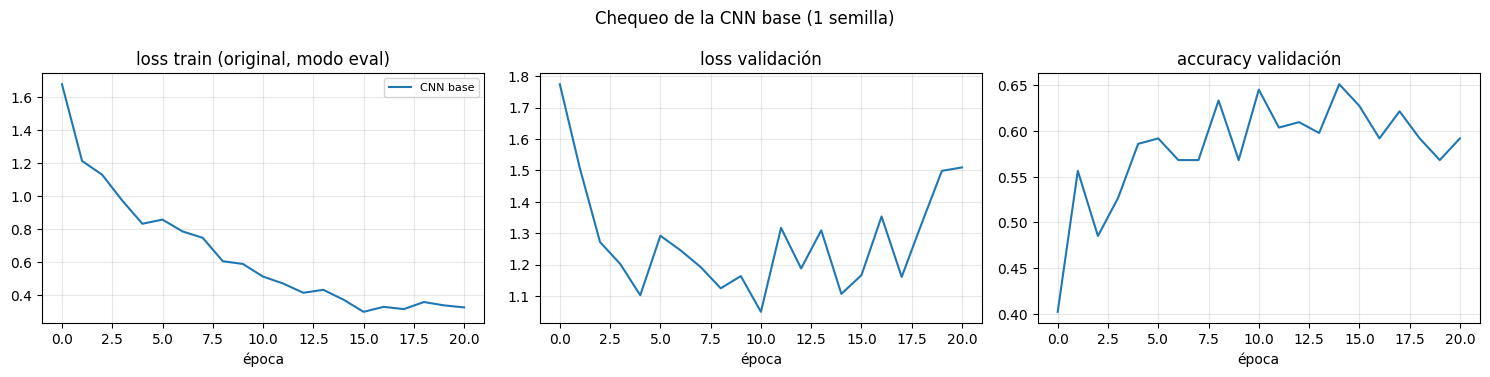

In [15]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0333,0.4346,0.0605
1,MLP 64px,6358793,0.5247,0.0433,0.7042,0.1796,6.6667,0.0604,0.4372,0.0874
2,CNN 32px,156057,0.6252,0.0228,0.7912,0.1659,7.6667,0.0576,0.5582,0.0671
3,CNN 64px,549273,0.6331,0.0211,0.8063,0.1732,11.6667,0.0757,0.5510,0.0822


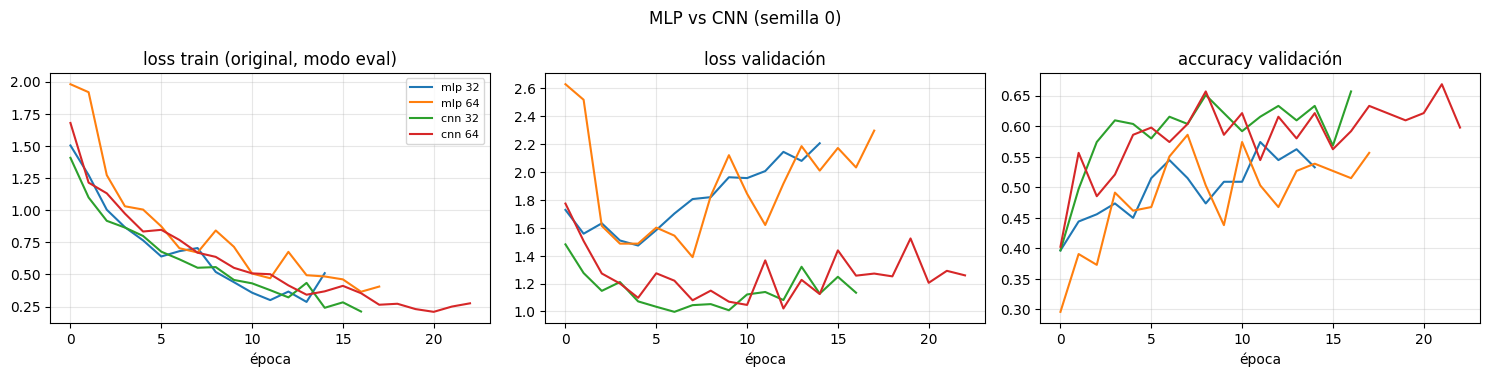

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [16]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

**1. Comparación.**

| | params | val_acc | brecha | mejor época | s/época |
|---|---|---|---|---|---|
| MLP 32 | 1 640 201 | 0.495 ± 0.039 | 0.243 | 5.0 | 0.033 |
| MLP 64 | 6 358 793 | 0.525 ± 0.043 | 0.180 | 6.7 | 0.060 |
| CNN 32 | 156 057 | 0.625 ± 0.023 | 0.166 | 7.7 | 0.058 |
| CNN 64 | 549 273 | 0.633 ± 0.021 | 0.173 | 11.7 | 0.076 |

La CNN tiene **10× (32 px) a 12× (64 px) menos parámetros** y aun así mejora la val_acc en **+0.13 (32 px) y +0.11 (64 px)**. Esa diferencia es ~3 veces el error estándar de la validación (0.038 con 169 imágenes), entre 2 y 3 veces el ruido combinado entre semillas (√(0.043² + 0.021²) ≈ 0.048 a 64 px; 0.045 a 32 px) y ~5 veces la dispersión de la propia CNN base entre secciones (~0.02), así que **es real**. La MLP tiene más brecha (0.18-0.24 contra 0.17) y converge antes (5-7 épocas): en las curvas su `val_loss` toca el mínimo enseguida y sube rápido (de ~1.5 a 2.2-2.3) mientras la train loss sigue bajando, o sea que memoriza píxeles. La CNN tarda algo más por época (0.076 contra 0.060 s a 64 px), porque una convolución hace más operaciones por parámetro, pero en valores absolutos todo es despreciable en GPU. Entre 32 y 64 px no hay diferencia dentro de cada modelo (0.625 contra 0.633 y 0.495 contra 0.525, ambas menores que el ruido).

**2. Parámetros de la primera capa de la MLP.** Con entrada `3·s·s` y 512 neuronas:
- 32 px: 3·32·32 = 3072 → 3072·512 + 512 = **1 573 376** (el 96 % de los 1 640 201).
- 64 px: 12 288 → 12 288·512 + 512 = **6 291 968** (verificado: + 65 664 + 1161 = 6 358 793 ✔).
- 224 px: 150 528 → 150 528·512 + 512 = **77 070 848 solo en la primera capa**, imposible de entrenar con 506 imágenes.

El número crece con el cuadrado del lado porque cada píxel de cada canal es una variable independiente con su propio peso hacia cada neurona. La convolución lo cambia por dos propiedades: **conectividad local** (cada neurona mira solo un parche de k×k, no la imagen entera) y **pesos compartidos** (el mismo filtro se aplica en todas las posiciones). La primera conv tiene 3·16·3·3 = 432 parámetros con cualquier tamaño de imagen. En la CNN lo único que crece con la resolución es la `Linear` de la cabeza.

**3. Robustez a traslaciones.** Caídas: MLP 32 = 0.061, CNN 32 = 0.067, MLP 64 = 0.087, CNN 64 = 0.082. **No hay diferencia entre modelos**: son iguales dentro de ±0.006, muy por debajo del error estándar. En términos relativos la CNN 64 cae algo menos (13 % contra 17 % de la MLP 64), pero tampoco es concluyente. Esto no contradice la teoría, porque esta CNN **no es invariante a traslaciones**: la convolución es equivariante (el mapa se desplaza junto con la imagen), pero el MaxPool solo da invarianza local (~2 px por bloque) y después la cabeza hace `Flatten → Linear`, que asigna un peso distinto a cada posición del mapa de 8×8. Una traslación de 8 px desplaza el mapa final una celda completa y la `Linear` ve otra cosa. Además, `torch.roll` es circular: el borde que sale por un lado entra por el otro y crea costuras artificiales que ninguno de los dos modelos vio. Para obtener invarianza real haría falta un *global average pooling* antes de la cabeza. Lo que sí se ve es que la CNN sigue siendo mucho mejor con las imágenes trasladadas (0.55 contra 0.44).

**4. Normalización.** Cada canal se estandariza con media y desvío calculados **solo con las imágenes de train** (a 64 px: media [0.743, 0.572, 0.565], desvío [0.162, 0.164, 0.186]), para que nada de val/test se filtre al preprocesamiento. Las imágenes son muy rojizas y claras (R medio 0.74), así que sin normalizar las entradas estarían todas en [0, 1], positivas y descentradas, con el canal R dominando. Eso hace que los gradientes de la primera capa tengan todos el mismo signo y que la optimización sea más lenta e inestable, sobre todo con Adam a lr = 3e-3 y sobre todo en la MLP, que no tiene BatchNorm. La CNN lo sufriría menos porque la BatchNorm re-normaliza después de cada conv, aunque la primera conv seguiría recibiendo entradas mal escaladas.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6489,0.0170,0.8327,0.1838,12.3333,0.0805,1.8031
1,2 bloques,8,1055001,0.6114,0.0148,0.7846,0.1731,11.3333,0.0670,1.4182
2,4 bloques,38,361113,0.6174,0.0155,0.7628,0.1455,13.6667,0.0858,2.0273
3,kernel 5,32,591001,0.6154,0.0317,0.8123,0.1969,16.3333,0.0842,2.2244
4,kernel 7,46,653593,0.5641,0.0366,0.7207,0.1566,15.3333,0.1136,2.8738
5,8 filtros,18,269521,0.6430,0.0433,0.8353,0.1923,10.0000,0.0714,1.4266
6,32 filtros,18,1143337,0.6036,0.0174,0.7951,0.1916,14.0000,0.1140,2.7389
7,32 px,18,156057,0.6588,0.0405,0.7997,0.1410,7.6667,0.0595,1.0541
8,96 px,18,1204633,0.5838,0.0266,0.6937,0.1098,11.0000,0.1178,2.4795


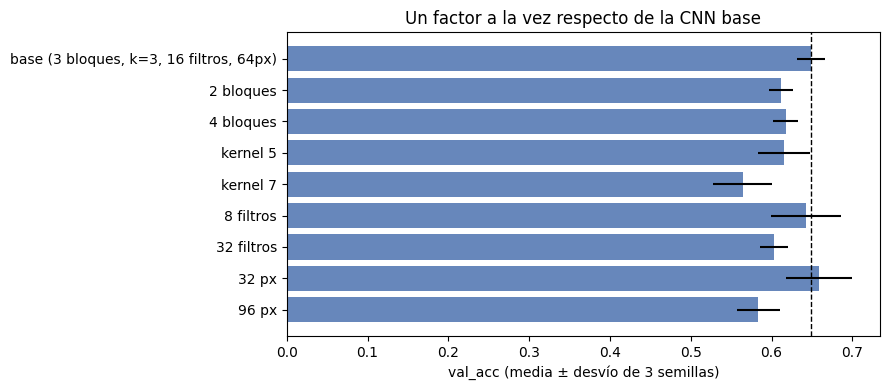

In [17]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

**1. Qué supera el ruido.** La base dio 0.649 ± 0.017. Los desvíos van de 0.015 a 0.043, el error estándar de val es 0.038, y la misma base dio 0.633 y 0.631 en otras secciones. Por eso tomo como real solo una diferencia de más de ~0.04-0.05.
- **Claramente peores:** *kernel 7* (0.564, **−0.085**) y *96 px* (0.584, **−0.065**).
- **En el límite (~1 error estándar, no concluyente):** *32 filtros* (−0.045), *2 bloques* (−0.038), *kernel 5* (−0.034), *4 bloques* (−0.032).
- **Indistinguibles de la base:** *8 filtros* (−0.006, con el desvío más grande, 0.043) y *32 px* (**+0.010**, desvío 0.041).

Ninguna variante es mejor que la base de forma demostrable. La "mejor arquitectura" que elige la sección 8 (32 px) le gana a la base por una diferencia cuatro veces menor que su propio desvío: en la práctica es un empate. Igual es una elección razonable por parsimonia, porque tiene 3.5× menos parámetros (156 057) y es la más rápida (1.05 s por entrenamiento).

**2. Profundidad y kernel.** Campos receptivos: 2 bloques = 8 px, base = 18 px, 4 bloques = 38 px, kernel 5 = 32 px, kernel 7 = 46 px, sobre una imagen de 64 px (13 %, 28 %, 59 %, 50 % y 72 % del lado). Las lesiones ocupan buena parte del cuadro y la asimetría y la forma del borde son globales, así que esperaba que un campo receptivo mayor (4 bloques o kernel más grande) ayudara. **No se observó:** 4 bloques y kernel 5 quedan dentro del ruido y kernel 7 empeora. Mi explicación: en esta arquitectura la conv no es la única vía para integrar información global, porque la `Linear` de la cabeza ya ve todo el mapa de 8×8. Con 506 imágenes de train, filtros más grandes (k = 7 tiene 5.4× más pesos por filtro que k = 3) son más difíciles de ajustar: kernel 7 tiene *menor* train_acc (0.72 contra 0.83), así que no sobreajusta sino que aprende peor. En costo, kernel 7 tarda 0.114 s/época contra 0.081 (+40 %) y suma 104 k parámetros, para perder 8 puntos. 2 bloques empeora con el doble de parámetros (1 055 001), porque con un solo pooling menos la `Linear` recibe 32·16·16 = 8192 entradas. 4 bloques tiene *menos* parámetros (361 113) porque la cabeza se achica a 128·4·4 = 2048 entradas, pero tampoco mejora.

**3. Resolución de entrada.** Con 3 bloques `fs = size // 8`, y la `Linear` tiene `64·fs²·128 + 128` parámetros: 32 px → 64·4·4 = 1024 entradas → **131 200**; 64 px → 4096 → **524 416**; 96 px → 9216 → **1 179 776**. Crece con el cuadrado del lado porque la conv no reduce el tamaño de la imagen, solo lo hacen los pooling, que son fijos. Las convs son las mismas (23 696 parámetros) en los tres casos. Al subir la resolución se gana detalle fino (red pigmentaria, puntos, vasos) y se pierden cómputo (0.060 → 0.081 → 0.118 s/época) y campo receptivo *relativo*: los mismos 18 px cubren el 56 % del lado a 32 px, el 28 % a 64 px y solo el 19 % a 96 px. Resultado: 32 px (0.659) ≈ 64 px (0.649) > 96 px (0.584). A 96 px la train_acc también cae (0.69), así que el detalle extra no se aprovecha y la cabeza de 1.2 M parámetros es más difícil de entrenar. **Límite del experimento:** con ~60 imágenes por clase la red no tiene datos suficientes para aprender rasgos finos, así que el experimento mide sobre todo "cuántos parámetros puedo ajustar con 506 imágenes" y no "cuánto detalle diagnóstico hay a cada resolución". Además, si la red se apoya en artefactos de adquisición (fondo, viñetas, flash), esos se ven igual de bien a 32 px. Con más datos o con transfer learning el resultado podría invertirse.

**4. Límites del diseño.** Con "un factor a la vez" no se ven **interacciones**: más profundidad podría servir justamente a 96 px (para recuperar campo receptivo relativo), y el kernel y la resolución están acoplados. Tampoco se exploró el learning rate, que quedó fijo en 3e-3 y puede no ser óptimo para cada variante. Por eso la configuración final *greedy* (mejor arquitectura + mejor augmentation) no está garantizada como óptima. Con 3 semillas, el propio desvío está muy mal estimado (un desvío de 3 muestras puede variar al doble o a la mitad), y comparar 9 variantes contra la misma validación de 169 imágenes hace que la "mejor" tenga sesgo optimista. La comparación también depende de una única partición (`SEED_SPLIT=42`).

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6312,0.0195,0.7892,0.1580,1.0273,11.3333,0.0769,1.6292
1,flips,1518,0.5996,0.0101,0.7885,0.1889,1.0299,7.3333,0.2137,3.7019
2,flips+rot90,1518,0.6509,0.0256,0.8656,0.2147,1.0796,12.0000,0.2141,4.7214
3,flips+rot90+color,1518,0.6469,0.0122,0.8103,0.1633,1.0331,11.6667,0.2214,4.7744


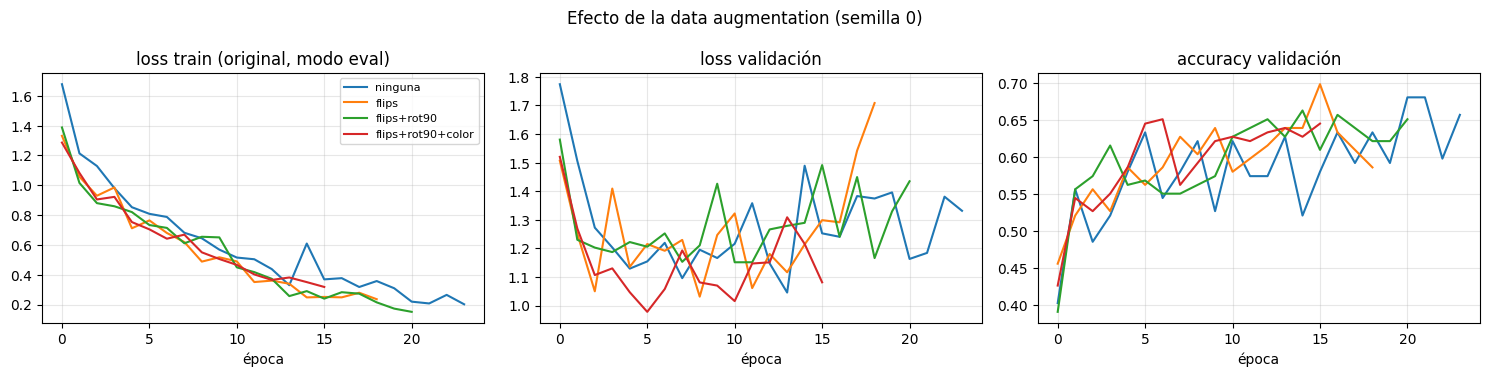

In [18]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

**1. Overfitting sin augmentation.** Sin augmentation la CNN llega a train_acc 0.789 contra val_acc 0.631: **brecha de 0.158**, medida en la mejor época, o sea ya con early stopping (sin él sería mayor). En el chequeo de la sección 4.2 (semilla 0), la `val_loss` llega a su mínimo (~1.05) en la **época 11** y después sube hasta ~1.5 en la época 21, mientras la loss de train sigue bajando de ~0.5 a ~0.3. En la curva "ninguna" de esta sección pasa lo mismo: train loss ~0.2 al final contra val_loss 1.2-1.5, y la `val_loss` oscila y sube desde la época ~13. Con ~60 imágenes por clase y 549 k parámetros, la red memoriza train.

**2. Efecto de cada nivel.**

| aug | n_train | val_acc | brecha | val_loss | época | t total |
|---|---|---|---|---|---|---|
| ninguna | 506 | 0.631 ± 0.020 | 0.158 | 1.027 | 11.3 | 1.6 s |
| flips | 1518 | 0.600 ± 0.010 | 0.189 | 1.030 | 7.3 | 3.7 s |
| flips+rot90 | 1518 | 0.651 ± 0.026 | 0.215 | 1.080 | 12.0 | 4.7 s |
| +color | 1518 | 0.647 ± 0.012 | 0.163 | 1.033 | 11.7 | 4.8 s |

**Ninguna mejora supera el ruido.** flips+rot90 (+0.020) y +color (+0.016) están por debajo del desvío (~0.02), del error estándar (0.038) y de la variación de la propia base entre secciones (0.631-0.649). La caída de flips (−0.031) tampoco es creíble como efecto real, porque no tiene sentido que flips empeore y flips+rot90 mejore. La `val_loss` no mejora (1.027 → 1.03-1.08) y **la brecha no se achica, crece** (0.158 → 0.19-0.215, salvo con color: 0.163). Contra lo esperado, la augmentation no redujo el overfitting en esta corrida. Mis explicaciones: (a) las copias se generan **una sola vez** (2 copias fijas por imagen), así que la red ve siempre las mismas 3 versiones y puede memorizarlas igual; es como triplicar el dataset con casi-duplicados, no augmentation *on the fly*; (b) la train_acc se mide sobre las imágenes originales, que están dentro del set aumentado; (c) cada época tiene 3× más pasos de gradiente, así que "7.3 épocas" de flips equivalen a ~22 pasadas por las imágenes originales. Por eso **cada época cuesta ~2.8× más** (0.077 → 0.214 s): son 1518 imágenes en lugar de 506 (48 batches contra 16). La transformación no se calcula durante el entrenamiento, ya está precalculada. El tiempo total también se triplica (1.6 → 4.7 s).

**3. Dominio.** *Flips y rotaciones de 90°* tienen sentido para dermatoscopía: la lesión vista por el dermatoscopio no tiene orientación privilegiada y el diagnóstico (asimetría, borde, estructuras) no cambia al rotarla. Para las fotos clínicas (*Atopic*, *Tinea*: brazos, piernas) sí hay una orientación natural, pero la etiqueta tampoco cambia. *El color es información diagnóstica* (red pigmentaria marrón/negra, velo azul-blanquecino del melanoma, rojo/violeta de las lesiones vasculares), así que cambios de tono (*hue*) destruirían información. El brillo/contraste moderado (±20 %, el mismo factor para los tres canales) es aceptable porque simula iluminaciones o cámaras distintas sin cambiar el tono. *La escala* también es delicada: el diámetro es un criterio clínico (la "D" del ABCDE), aunque sin una regla en la imagen la escala absoluta ya es desconocida. Otras que probaría: rotaciones de ángulo arbitrario con recorte central, recortes y traslaciones chicas, desenfoque leve (foco del dermatoscopio), **máscaras o viñetas circulares aleatorias** para romper el atajo de la viñeta que separa nevus/melanoma del resto, normalización de color (*color constancy*) en lugar de solo perturbarlo, y sobre todo **augmentation aleatoria en cada época** en lugar de copias fijas.

**4. Después del split y solo en train.** Si se aumentara antes de dividir, las copias rotadas o volteadas de una misma imagen quedarían repartidas entre train, val y test: sería el mismo problema que los 34 duplicados del EDA, pero multiplicado. Val y test estarían llenos de versiones de imágenes que el modelo ya vio, la val_acc y la test_acc saldrían infladas y elegiríamos modelos por su capacidad de memorizar. Val y test no se aumentan porque tienen que representar la distribución real de imágenes que va a recibir el modelo. Por la misma razón, la normalización se calcula solo con train.

**5. Comparación con el TP3.** Dropout y L2 restringen el *modelo*: limitan el tamaño de los pesos o fuerzan redundancia, pero no le dan información nueva sobre el problema. La augmentation regulariza agregando *datos*: le codifica a la red un conocimiento del dominio ("la etiqueta no cambia si roto la lesión") que de otra forma tendría que aprender sola con pocos ejemplos. Por eso su efecto depende de que la invarianza supuesta sea verdadera, y puede perjudicar si no lo es (por ejemplo, con cambios de tono). Son complementarias: acá la CNN ya tiene Dropout 0.2 y BatchNorm, y la augmentation con copias fijas no agregó una mejora medible.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [19]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 32 px | mejor augmentation (val): flips+rot90
Config final: {'model': 'cnn', 'size': 32, 'n_blocks': 3, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90'}
Config final en validación: val_acc 0.663 ± 0.010 | brecha 0.134 | mejor época 5.7 | 3s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,156057,0.6982,0.0365,0.6929,0.0364,3.3392
1,MLP 64px,6358793,0.5041,0.0534,0.4872,0.0572,0.9493


Error estándar binomial del test (169 imágenes): ±0.035 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.67      0.60      0.63        20
         Atopic Dermatitis       0.93      0.81      0.87        16
          Benign keratosis       0.95      0.95      0.95        20
            Dermatofibroma       0.67      0.70      0.68        20
         Melanocytic nevus       0.73      0.55      0.63        20
                  Melanoma       0.59      0.65      0.62        20
   Squamous cell carcinoma       0.50      0.70      0.58        20
Tinea Ringworm Candidiasis       0.67      0.62      0.64        13
           Vascular lesion       0.95      0.90      0.92        20

                  accuracy                           0.72       169
                 macro avg       0.74      0.72      0.73       169
              weighted avg       0.74      0.72      0.73       169



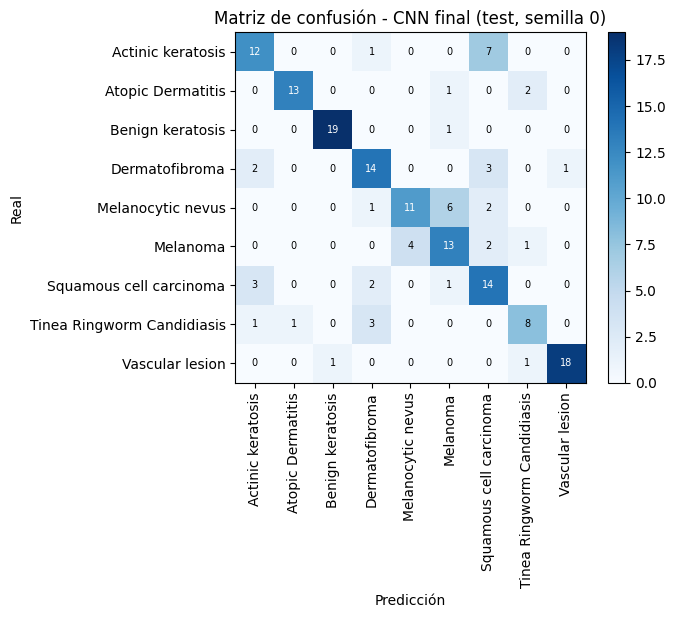

In [20]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

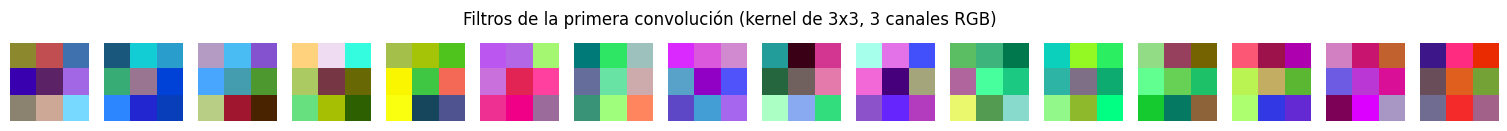

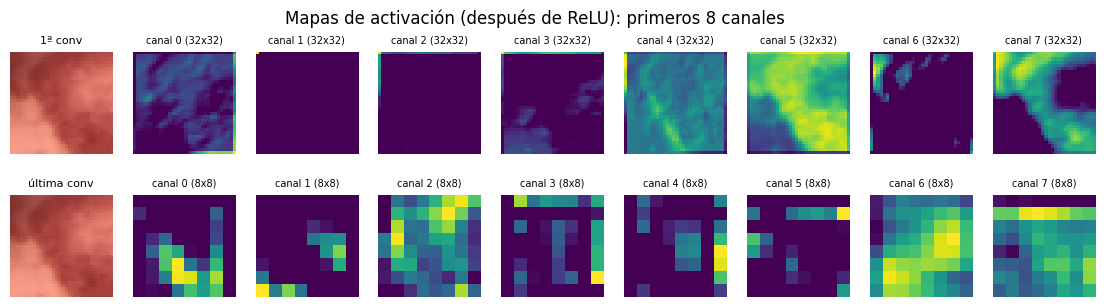

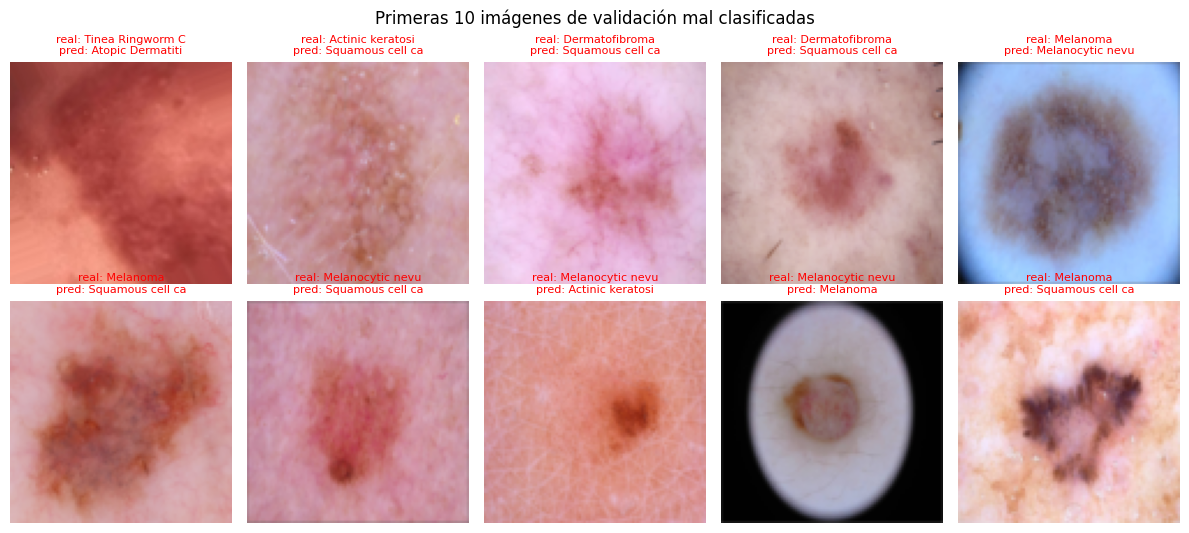

In [21]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

**1. Val contra test.** Config final: CNN de 3 bloques, k = 3, 16 filtros, **32 px**, augmentation **flips+rot90** (elegida automáticamente, sin `FINAL_OVERRIDE`). En validación: 0.663 ± 0.010 (3 semillas). En test: **0.698 ± 0.037** (5 semillas), F1 macro 0.693 ± 0.036. La diferencia (+0.035) es exactamente 1 error estándar del test (±0.035 con 169 imágenes), así que **son coherentes**. Por el sesgo optimista de elegir la mejor configuración sobre validación esperaba que test diera *menos*, y dio algo más. Que no se vea ese sesgo es compatible con que las diferencias entre configuraciones eran casi todas ruido: si todas son prácticamente iguales, elegir la "mejor" casi no infla nada. La combinación final tampoco mejoró en validación a sus partes (0.663 contra 0.659 de 32 px solo y 0.651 de flips+rot90 sola).

**2. CNN contra MLP en test.** CNN 0.698 ± 0.037 contra MLP 64 px 0.504 ± 0.053: **+0.194 de accuracy y +0.206 de F1 macro** (0.693 contra 0.487). Es ~5 veces el error estándar del test y ~3 veces el ruido combinado entre semillas (√(0.037² + 0.053²) ≈ 0.065), así que **la diferencia es real y grande**. El costo también favorece a la CNN: **40× menos parámetros** (156 057 contra 6 358 793). Solo tarda más en entrenar (3.3 s contra 0.95 s, por el set aumentado 3× y por más épocas), una diferencia irrelevante en valores absolutos. Se justifica sin dudas.

**3. Matriz de confusión** (semilla 0, accuracy 0.72). Las confusiones principales son *Actinic keratosis → SCC* (**7** de 20), *Melanocytic nevus → Melanoma* (**6**), *Melanoma → nevus* (**4**), *SCC → AK* (3), *Dermatofibroma → SCC* (3) y *Tinea → Dermatofibroma* (3). Tienen sentido clínico: la queratosis actínica es una lesión precursora del carcinoma espinocelular (ambas son queratinocíticas, rosadas y descamativas), y nevus contra melanoma es el diagnóstico diferencial clásico de las lesiones melanocíticas. Pero también coinciden con el EDA: **las confusiones pasan dentro de grupos que comparten fuente de adquisición** (AK/DF/SCC/VL a 600×450; nevus/melanoma a 1024×768 con viñeta). Las clases con mejor F1 son *Benign keratosis* (0.95), *Vascular lesion* (0.92) y *Atopic Dermatitis* (0.87). Vascular tiene un color rojo/violeta realmente distintivo, pero BK y Atopic son justamente las que tienen artefactos propios (flash lateral; fotos clínicas de 294×222 con fondo azul), lo que sugiere que parte del acierto viene de atajos. *SCC* funciona como clase "por defecto" para lesiones rosadas ambiguas: recibe 14 falsos positivos y tiene precisión 0.50.

**No todas las confusiones son igual de graves:** un melanoma clasificado como nevus (falso negativo) retrasa el diagnóstico de un cáncer potencialmente letal, mientras que un nevus clasificado como melanoma cuesta una biopsia innecesaria. Acá el **recall de melanoma es 0.65**: 7 de 20 melanomas no se detectaron y 4 de ellos se clasificaron como nevus benigno. La métrica más relevante sería la **sensibilidad (recall) de las clases malignas** (melanoma, SCC y AK como premaligna), o la sensibilidad de un problema binario maligno/benigno a una especificidad fija, eventualmente con una matriz de costos. La F1 macro es mejor resumen general que el accuracy porque pesa igual a las clases chicas (Tinea con 13 imágenes de test, Atopic con 16), aunque como el test está casi balanceado acá dan parecido (0.693 contra 0.698).

**4. Filtros, activaciones y errores.** Los 16 filtros de la primera conv son de 3×3 y difíciles de interpretar uno por uno, pero se ven como **detectores de color y contraste** (combinaciones opuestas tipo magenta/verde y patrones claro/oscuro). Sus mapas de activación (32×32) conservan la geometría de la imagen: algunos canales responden a las zonas claras u oscuras de la lesión (canales 5 y 7), otros a los bordes (canal 4), varios están casi apagados (1 y 2) y varios se encienden en el **borde de la imagen**, un artefacto del padding con ceros. En la última conv los mapas son de **8×8**, ralos y abstractos: cada celda resume un parche de 18 px (más de la mitad de una imagen de 32 px), ya no se reconoce la imagen y las activaciones representan presencia de rasgos combinados, no píxeles. En las imágenes mal clasificadas se repiten: **lesiones de bajo contraste** sobre piel rosada (AK, DF), **casos sin piel alrededor** (la Tinea en primer plano predicha como Atopic), **melanomas y nevus que comparten viñeta o tipo de imagen** (melanoma con viñeta azul → nevus; nevus con viñeta negra → melanoma), y **6 de las 10 predichas como SCC**. A 32 px se pierden estructuras dermatoscópicas finas (red pigmentaria, puntos, vasos) que son justamente las que separan esos pares.

**5. Sesgos y limitaciones.**
- **Sesgo de adquisición:** la resolución, el fondo, la viñeta y el flash están ligados a la clase (EDA, punto 2) y el color medio de Atopic refleja el fondo de la foto clínica, no la piel. Es probable que parte del ~70 % se deba a reconocer la fuente, y no generalizaría a imágenes de otro hospital o dispositivo.
- **Duplicados:** se eliminaron los 34 exactos (que habrían inflado la val_acc de Atopic y Tinea), pero el dataset no tiene identificador de paciente ni de lesión. Fotos distintas de una misma lesión (con otro recorte o encuadre) no se detectan con MD5 ni con un hash perceptual de umbral ≤ 8 bits. En la galería del EDA algunas imágenes de AK y de Tinea parecen ser la misma lesión. Si caen en particiones distintas, el test queda inflado.
- **Tamaño y diseño:** 844 imágenes, 506 de train (~60 por clase), val y test de 169 (error estándar ≈ 0.035-0.038), una sola partición (`SEED_SPLIT=42`), 3 semillas para elegir y la misma validación reutilizada para comparar 13 configuraciones. Además, la GPU no es determinista (la misma config varió entre 0.631 y 0.649).

**Con más tiempo:** validación cruzada estratificada (idealmente agrupada por paciente o lesión) en lugar de una sola partición; más semillas; augmentation aleatoria en cada época; una cabeza con *global average pooling*; **transfer learning** con una red preentrenada a mayor resolución; controles contra el atajo de adquisición (recortar o enmascarar viñetas y bordes, normalizar el color, mirar mapas tipo Grad-CAM para ver si la red mira la lesión o el fondo); una pérdida o un umbral sensibles al costo para subir el recall de melanoma; y evaluar en un dataset externo (por ejemplo, el ISIC completo, con ~25 000 imágenes).

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

Si, utilice Claude code para mejorar la redación de los analisis y explicaciones en el trabajo.